> **中文阅读版**：本文件是 `21_storage_benchmark_database.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 存储基准测试：数据库引擎

**Docker 镜像**：`benchmark`

> **需要 Docker**：本 Notebook 依赖 `benchmark` 环境及
> 数据库服务。运行方式：
> ```bash
> docker compose --profile benchmark up -d timescaledb clickhouse questdb influxdb
> docker compose --profile benchmark run --rm benchmark python 02_financial_data_universe/21_storage_benchmark_database.py
> ```

**重点**：支持查询的金融时间序列数据库

## 数据库类别

| 类别 | 示例 | 特点 |
|----------|----------|-----------------|
| **嵌入式** | SQLite, DuckDB, ArcticDB | 进程内，无需服务器 |
| **时间序列服务器** | ClickHouse, QuestDB, TimescaleDB | 生产规模，需要 Docker |
| **通用型** | PostgreSQL, InfluxDB | 基线对比 |
| **HFT 专用** | kdb+/PyKX | 交易行业标准 |

## 基准测试的操作

1. **写入** - 批量插入性能
2. **读取** - 全表扫描
3. **范围查询** - 7 天时间窗口（回测工作流）
4. **OHLCV 聚合** - 将分钟 bar 重采样为日 bar
5. **ASOF Join** - 成交-报价对齐（对市场微观结构至关重要）

## 计时策略

采用同一套策略，并同样应用于每个引擎。若不同引擎按不同规则计时，它们就不应出现在同一张图上，因此这里明确规则，并由 `time_write` / `time_read` 辅助函数强制执行，而不是通过每次调用的参数来指定：

- **写入**（`time_write`）- 针对每次运行新建的表，单次执行，无预热。批量加载对每个数据集只发生一次，因此我们计时的就是这一次加载。重复执行会在仅追加（append-only）引擎上追加重复行，或需要执行一次不属于写入环节的 teardown。
- **写入 bar 反映的是客户端付出的代价，而各客户端并不相同。** SQLite、DuckDB、ClickHouse 和 kdb+ 以整块方式接收面板数据（`to_sql`、Parquet 扫描、`insert_df`、`set`）。PostgreSQL 和 TimescaleDB 必须为 `execute_values` 逐行构造一个 Python tuple，InfluxDB 则必须为 line protocol 逐行构造一个 `Point`。这种构造正是使用这些接口的成本，因此它保留在计时区间内，而且这三者还各自单独测量该成本并打印其占比；图表上方的表格汇总了这些数据。这三个数字只是*显式*行构造的耗时，仅此而已。每个客户端都会在某处进行转换和序列化——`to_sql` 仍会逐行准备并绑定，`insert_df` 仍会序列化 DataFrame——而这些都无法从外部剥离，因此没有测得占比的 bar 并不代表全部耗时都来自引擎。请把每个写入 bar 理解为“通过该引擎的 Python 客户端将此面板数据写入该引擎的成本”，绝不要理解为引擎的摄取速率。
- **计时区间内的持久性。** PostgreSQL 和 TimescaleDB 同步提交，因此其 flush 成本包含在计时调用内。QuestDB（ILP + WAL）和 InfluxDB 在行可查询之前就返回确认，因此它们在计时调用*内部*通过 `wait_until_rows_visible` 轮询直到首次可查询。因此每次写入计时都结束于同一事件：数据已持久化且可读。
- **读取、聚合和连接**（`time_read`）- 在一次不计时的预热之后，取 `TIMING_RUNS` 次运行的平均值。**这些是热缓存数字**，既位于操作系统页缓存，也位于每个服务器的缓冲池中，并且会让每个带缓存的引擎显得更好。客户端无法清除服务器的缓存，因此这里的“冷”读取对嵌入式引擎来说是冷的，而对服务器来说却是热的——既非冷读，也不可比。热且统一是可测量的选择；§2.4 在报告这些数字时说明了这一点。
- **每次读取都会按预期行数进行精确校验。** 下面的每个查询都是确定性的，且其答案在运行前已知，因此接近但不完全匹配就是错误答案，而不是可容忍的答案——否则，一个静默返回截断结果的查询就会在图表上刷出最快时间。

## 大小列表示什么、不表示什么

与计时不同，每个引擎的磁盘占用大小**并非**以相同方式测量，因为每个引擎只暴露自己的统计口径。请将大小列理解为“该引擎报告自己正在使用的量”，而不是同口径的压缩比：

| 引擎 | 报告来源 | 统计内容 |
|--------|-------------|--------|
| SQLite / DuckDB | 磁盘文件大小 | 数据库文件 |
| ClickHouse | `system.parts.bytes_on_disk` | **压缩后的**数据 parts |
| QuestDB | `table_storage().diskSize` | 表的完整磁盘占用 |
| PostgreSQL / TimescaleDB | `pg_total_relation_size` / `hypertable_size` | 表**加索引**（对于 hypertable，还包括其所有 chunk） |
| InfluxDB | *未暴露* | 客户端 API 不报告每个 bucket 的大小，因此留空，而不是记录为零 |

将 ClickHouse 的压缩 parts 与 PostgreSQL 的表加索引总量相比，并不是压缩率比较。文件格式 Notebook(`20_storage_benchmark_file`) 是在各参与方之间以相同方式度量大小、并可直接比较的地方。

## 快速开始

```bash
# Embedded engines only. DuckDB and SQLite need nothing beyond the base install.
uv run python 02_financial_data_universe/21_storage_benchmark_database.py

# With the server engines as well, from the host (compose publishes their ports)
docker compose --profile databases up -d timescaledb postgres clickhouse questdb influxdb
uv run --extra db-benchmark python 02_financial_data_universe/21_storage_benchmark_database.py
```

`db-benchmark` extra 还包含 ArcticDB，而 ArcticDB 不发布 Linux ARM64 wheel，也没有源码分发包。在 ARM64 上，安装会在 notebook 能运行之前就失败，因此可选导入保护根本没有机会跳过它：请使用上面的 Docker 路径，其中的 `benchmark` 镜像会随附服务器客户端，但不含 ArcticDB。

规模由下面的 `BENCHMARK_SCALE` 参数决定，而不是环境变量：参数单元格之后的单元格会把该参数写回环境，供 `utils.storage_benchmarks` 读取，因此命令行上的 `BENCHMARK_SCALE=...` 前缀会在任何代码读取它之前被覆盖。要更改规模，请编辑该参数，或像 CI 那样用 Papermill 注入它。

无论哪些引擎有响应，底部的覆盖报告都会列出在本页产生这些数字的引擎，以及没有产生数字的引擎。

## 设置

In [1]:
"""Storage Benchmark — Database engine comparison for financial time-series."""

import contextlib
import gc
import json
import os
import shutil
import sqlite3
import subprocess
import time as time_module
import urllib.parse
import urllib.request
from datetime import UTC, timedelta
from pathlib import Path

### 声明的参数

`BENCHMARK_SCALE` 选择面板大小；生产设置是 §2.4 引用的那个，CI 通过 Papermill 将其覆盖为小规模。每个报告数字的单元格也会报告产生该数字的规模，因此从本页摘取的数字会自带其来源。

`RANGE_QUERY_SHARE` 是范围查询应选择的面板比例。它是比例而不是固定天数，因为面板的日历跨度会随规模增长：固定的七天窗口会选择大面板的五分之一，并选择小面板的*全部*，这会悄然把图表的范围查询面板变成全量扫描的第二份副本。

`LOG_AXIS_RATIO` 是图表面板切换到对数 x 轴时的分布跨度，按实际绘制的柱状条测量，而不是根据过去的运行假定。

In [2]:
BENCHMARK_SCALE = "L"
RANGE_QUERY_SHARE = 0.2
LOG_AXIS_RATIO = 10.0

`utils.storage_benchmarks` 在导入时会从环境读取规模，因此必须在导入之前设置该变量，而不是之后将其传给函数。

In [3]:
os.environ["BENCHMARK_SCALE"] = BENCHMARK_SCALE

import pandas as pd
import plotly.graph_objects as go
import polars as pl
from plotly.subplots import make_subplots

from utils.paths import display_path, get_output_dir
from utils.storage_benchmarks import (
    ACTIVE_SCALE,
    BENCHMARK_DIR,
    DB_CONFIG,
    N_ROWS_PER_SYMBOL,
    N_SYMBOLS,
    N_TICKS_QUOTES,
    N_TICKS_TRADES,
    TIMING_RUNS,
    WAL_FLUSH_TIMEOUT,
    BenchmarkResult,
    estimate_memory_mb,
    force_materialize_pandas,
    force_materialize_polars,
    generate_ohlcv_data,
    generate_tick_data,
    get_scale_config,
    save_benchmark_results,
    save_chart,
    time_read,
    time_write,
    validate_result,
    wait_until_rows_visible,
)
from utils.style import COLORS, show_plotly_with_alt

In [4]:
OUTPUT_DIR = get_output_dir(2, "storage_benchmark")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 检查可用数据库

In [5]:
benchmark_status = {
    # Embedded (always available if package installed)
    "SQLite": {"expected": True, "tested": False, "category": "embedded"},
    # DuckDB is imported unconditionally below, so its absence raises rather than
    # lowering the bar this run is measured against.
    "DuckDB": {"expected": True, "tested": False, "category": "embedded"},
    "ArcticDB": {"expected": False, "tested": False, "category": "embedded"},
    # Servers (need Docker)
    "ClickHouse": {"expected": True, "tested": False, "category": "server"},
    "QuestDB": {"expected": True, "tested": False, "category": "server"},
    "TimescaleDB": {"expected": True, "tested": False, "category": "server"},
    "InfluxDB": {"expected": True, "tested": False, "category": "server"},
    "PostgreSQL": {"expected": True, "tested": False, "category": "server"},
    "kdb+/PyKX": {"expected": False, "tested": False, "category": "hft"},
}

print("=" * 70)
print(f"DATABASE BENCHMARK - Scale: {ACTIVE_SCALE}")
print("=" * 70)

DATABASE BENCHMARK - Scale: L


### 存在哪些引擎

DuckDB 同时随 `benchmark`（ARM64）和 `benchmark-full`（x86）镜像提供，SQLite 随 Python 提供，因此两者始终可用；notebook 在缺少 DuckDB 时会拒绝继续，而不是悄悄将其丢弃。ArcticDB 仅支持 x86，位于 `benchmark-full` 中；在它缺失的地方会报告为缺失。

In [6]:
try:
    import duckdb  # noqa: F401
except ImportError as exc:
    raise ImportError(
        "DuckDB is not available in the current image.\n"
        "This notebook runs in the `benchmark` image:\n"
        "  docker compose --profile benchmark run --rm benchmark \\\n"
        "      python 02_financial_data_universe/21_storage_benchmark_database.py"
    ) from exc

print("\n### Embedded Databases")
print("[OK] DuckDB: Available")
print("[OK] SQLite: Available (built-in)")


### Embedded Databases
[OK] DuckDB: Available
[OK] SQLite: Available (built-in)


下面的 ArcticDB 保护捕获的是 `Exception`，而不是 `ImportError`。已安装但无法运行的 ArcticDB 会抛出完全不同的异常——例如遇到不受支持的 protobuf 时抛出 `NotImplementedError`——而只捕获 `ImportError` 的保护会让这种异常终止 notebook。可选引擎必须在它可能无法使用的每一种方式上都是可选的，而不仅仅是在它可能缺失的那一种方式上。

In [7]:
try:
    import arcticdb as adb

    HAS_ARCTICDB = True
    benchmark_status["ArcticDB"]["expected"] = True
    print("[OK] ArcticDB: Available")
except Exception as exc:
    HAS_ARCTICDB = False
    print(f"○ ArcticDB: unavailable, skipping ({type(exc).__name__}: {exc})")

○ ArcticDB: unavailable, skipping (NotImplementedError: We only support protobuf versions 3, 4, 5 & 6. You have 7.35.0)


In [8]:
# === Check Server Databases ===
print("\n### Server Databases (Docker required)")

# ClickHouse
try:
    import clickhouse_connect

    ch_client = clickhouse_connect.get_client(
        host=DB_CONFIG["clickhouse"]["host"], port=DB_CONFIG["clickhouse"]["port"]
    )
    ch_client.query("SELECT 1")
    HAS_CLICKHOUSE = True
    print("[OK] ClickHouse: Available")
except Exception:
    HAS_CLICKHOUSE = False
    print("[FAIL] ClickHouse: Not available (start Docker)")

# QuestDB
try:
    urllib.request.urlopen(
        f"http://{DB_CONFIG['questdb']['host']}:{DB_CONFIG['questdb']['http_port']}/exec?query=SELECT%201",
        timeout=2,
    )
    HAS_QUESTDB = True
    print("[OK] QuestDB: Available")
except Exception:
    HAS_QUESTDB = False
    print("[FAIL] QuestDB: Not available (start Docker)")


### Server Databases (Docker required)
[OK] ClickHouse: Available
[OK] QuestDB: Available


In [9]:
# Check TimescaleDB and InfluxDB availability
try:
    import psycopg2

    ts_conn = psycopg2.connect(
        host=DB_CONFIG["timescaledb"]["host"],
        port=DB_CONFIG["timescaledb"]["port"],
        user=DB_CONFIG["timescaledb"]["user"],
        password=DB_CONFIG["timescaledb"]["password"],
        database=DB_CONFIG["timescaledb"]["database"],
        connect_timeout=2,
    )
    ts_conn.close()
    HAS_TIMESCALEDB = True
    print("[OK] TimescaleDB: Available")
except Exception:
    HAS_TIMESCALEDB = False
    print("[FAIL] TimescaleDB: Not available (start Docker)")

# InfluxDB
try:
    from influxdb_client import InfluxDBClient

    influx_test = InfluxDBClient(
        url=f"http://{DB_CONFIG['influxdb']['host']}:{DB_CONFIG['influxdb']['port']}",
        token=DB_CONFIG["influxdb"]["token"],
        org=DB_CONFIG["influxdb"]["org"],
        timeout=2000,
    )
    HAS_INFLUXDB = bool(influx_test.ready())
    influx_test.close()
    del influx_test
    if HAS_INFLUXDB:
        print("[OK] InfluxDB: Available")
    else:
        print("[FAIL] InfluxDB: Not ready")
except Exception:
    HAS_INFLUXDB = False
    print("[FAIL] InfluxDB: Not available (start Docker)")

[OK] TimescaleDB: Available
[OK] InfluxDB: Available


In [10]:
# PostgreSQL (vanilla, separate from TimescaleDB)
try:
    import psycopg2

    pg_conn_check = psycopg2.connect(
        host=DB_CONFIG["postgres"]["host"],
        port=DB_CONFIG["postgres"]["port"],
        user=DB_CONFIG["postgres"]["user"],
        password=DB_CONFIG["postgres"]["password"],
        database=DB_CONFIG["postgres"]["database"],
        connect_timeout=2,
    )
    pg_conn_check.close()
    HAS_POSTGRES = True
    print("[OK] PostgreSQL: Available")
except Exception:
    HAS_POSTGRES = False
    print("[FAIL] PostgreSQL: Not available (start Docker)")

[OK] PostgreSQL: Available


### 通过 PyKX 以 IPC 模式使用 kdb+

q 二进制文件和许可证会在导入 PyKX *之前*查找，这个顺序至关重要。绝不能以无许可证模式（`PYKX_UNLICENSED=1`）导入 PyKX。无许可证导入会让进程处于一种状态：后续 numpy 工作会发生段错误，而崩溃落在 `generate_ohlcv_data` 中，离导致它的导入位置很远，因此看起来像数据 bug。没有许可证就没有可基准测试的内容，所以完全不会导入 PyKX，并跳过 kdb+。

In [11]:
HAS_PYKX = False
Q_BINARY: Path | None = None

# Check multiple locations for q binary (host install or Docker mount)
Q_BINARY_LOCATIONS = [
    Path.home() / ".kx" / "bin" / "q",  # Standard location
    Path("/opt/kx/bin/q"),  # Alternative system location
]
KX_LICENSE_DIRS = [Path.home() / ".pykx", Path.home() / ".kx"]

for q_path in Q_BINARY_LOCATIONS:
    if q_path.exists() and q_path.is_file():
        Q_BINARY = q_path
        break

KX_LICENSE_FILE = next(
    (d / f for d in KX_LICENSE_DIRS for f in ("kc.lic", "k4.lic") if (d / f).exists()), None
)

if Q_BINARY is None or KX_LICENSE_FILE is None:
    print("○ PyKX/kdb+: Optional (not configured) — skipping, no result will be claimed")
    if Q_BINARY is None:
        print("    → Get a free personal edition: https://kx.com/kdb-personal-edition-download/")
        print(f"    → Install the q binary to: {display_path(Q_BINARY_LOCATIONS[0])}")
    if KX_LICENSE_FILE is None:
        print(f"    → Place the licence file (kc.lic) in: {display_path(KX_LICENSE_DIRS[0])}")
else:
    try:
        # q resolves its licence from QLIC, not from the file merely existing on
        # disk: without this the q process starts and dies "no license loaded".
        os.environ["QLIC"] = str(KX_LICENSE_FILE.parent)
        import pykx as kx

        HAS_PYKX = True
        benchmark_status["kdb+/PyKX"]["expected"] = True
        print(
            f"[OK] PyKX/kdb+ {kx.__version__}: Available "
            f"(IPC mode, licence {display_path(KX_LICENSE_FILE)})"
        )
    except Exception as exc:
        # As with ArcticDB: an optional engine that is present but unusable must not
        # end the run, whatever it raises on the way out.
        print(f"○ PyKX/kdb+: unavailable, skipping ({type(exc).__name__}: {exc})")

○ PyKX/kdb+: unavailable, skipping (ModuleNotFoundError: No module named 'pykx')


`expected` 将某个引擎标记为本章要比较的引擎。`available` 表示它在本机上通过了可用性检查。它们是不同的问题，混淆二者会把一台没有运行 Docker 的笔记本电脑变成一次报告五个失败的运行。下面的三个计数以及末尾的覆盖报告都是从状态表读取的，而不是写成字面量，因此向该表中添加一个引擎就完成了添加引擎的大部分工作。

In [12]:
AVAILABILITY = {
    "SQLite": True,
    "DuckDB": True,
    "ArcticDB": HAS_ARCTICDB,
    "ClickHouse": HAS_CLICKHOUSE,
    "QuestDB": HAS_QUESTDB,
    "TimescaleDB": HAS_TIMESCALEDB,
    "InfluxDB": HAS_INFLUXDB,
    "PostgreSQL": HAS_POSTGRES,
    "kdb+/PyKX": HAS_PYKX,
}
assert set(AVAILABILITY) == set(benchmark_status), (
    "every engine in the status table needs an availability flag"
)
for _engine, _is_available in AVAILABILITY.items():
    benchmark_status[_engine]["available"] = _is_available

n_embedded = sum(v["available"] for v in benchmark_status.values() if v["category"] == "embedded")
n_servers = sum(v["available"] for v in benchmark_status.values() if v["category"] == "server")
n_hft = sum(v["available"] for v in benchmark_status.values() if v["category"] == "hft")

print(f"\n[OK] {n_embedded} embedded + {n_servers} server + {n_hft} HFT database(s) available")

if n_servers == 0:
    print("\n[WARN]  No server databases. Start Docker containers:")
    print(
        "   docker compose --profile benchmark up -d timescaledb clickhouse questdb influxdb postgres"
    )


[OK] 2 embedded + 5 server + 0 HFT database(s) available


## 生成测试数据

In [13]:
scale_cfg = get_scale_config(ACTIVE_SCALE)
print(f"\nTarget: {scale_cfg['target_memory']} in-memory")
print(f"OHLCV: {N_SYMBOLS} symbols × {N_ROWS_PER_SYMBOL:,} rows/symbol")
print(f"Tick: {N_TICKS_TRADES:,} trades, {N_TICKS_QUOTES:,} quotes")

print("\n=== Generating synthetic data ===\n")

# Generate OHLCV data
ohlcv_df = generate_ohlcv_data(n_symbols=N_SYMBOLS, n_rows=N_ROWS_PER_SYMBOL)
total_rows = len(ohlcv_df)
memory_mb = estimate_memory_mb(ohlcv_df)
print(f"OHLCV data: {total_rows:,} rows ({memory_mb:.2f} MB)")

# Generate tick data for ASOF joins
trades_df, quotes_df = generate_tick_data(
    n_trades=N_TICKS_TRADES, n_quotes=N_TICKS_QUOTES, n_symbols=N_SYMBOLS
)
print(f"Tick data: {len(trades_df):,} trades, {len(quotes_df):,} quotes")

# pandas versions (some tools require pandas)
ohlcv_pandas = ohlcv_df.to_pandas()
trades_pandas = trades_df.to_pandas()
quotes_pandas = quotes_df.to_pandas()

# Results collection
results: list[BenchmarkResult] = []


Target: 100MB in-memory
OHLCV: 100 symbols × 10,000 rows/symbol
Tick: 500,000 trades, 2,500,000 quotes

=== Generating synthetic data ===



OHLCV data: 1,000,000 rows (63.90 MB)


Tick data: 500,000 trades, 2,500,000 quotes


### 度量被写出的行构造

PostgreSQL、TimescaleDB 和 InfluxDB 通过每行接收一个 Python 对象的接口访问其服务器，因此构造这些对象是通过它们写入的成本的一部分，并且仍留在计时的写入过程中。由于该构造是一个独立表达式，也可以单独计时，下面的辅助函数就是这样做的。返回的是这三个客户端各自占比的下界，而不是全部：客户端仍会转换并序列化交给它的内容，每个接口接收 frame 的客户端也是如此。这里没有度量这一点。

In [14]:
client_side_build: dict[str, float] = {}


def measure_row_build(engine: str, build) -> float:
    """Time an engine's client-side row construction in isolation."""
    gc.collect()
    started = time_module.perf_counter()
    rows = build()
    elapsed = time_module.perf_counter() - started
    del rows
    gc.collect()
    client_side_build[engine] = elapsed
    return elapsed


def report_row_build(engine: str, write_seconds: float) -> None:
    """Print an engine's client-side share of its own write time."""
    build_seconds = client_side_build[engine]
    print(
        f"  Client-side row building: {build_seconds:.3f}s of the {write_seconds:.3f}s "
        f"write ({build_seconds / write_seconds:.0%})"
    )

## 基准窗口

下面每个引擎都会复用两个派生量，使所有引擎回答 *同一个* 问题，并能用相同的预期行数进行验证：

- **范围查询**：面板的前若干个交易时段，即回测遍历的切片。窗口按面板的占比来设定，而不是固定数量的日历日，因为面板的时间跨度是规模的函数。七个日历日占大型面板的五分之一，却完全覆盖小型面板；而一个选中所有行的范围查询，不过是换个名字的全表扫描：图表会显示两个面板在衡量同一个查询，读者将无从分辨。按占比设定窗口，能让问题在每个规模下保持一致，下面的单元格会打印实际达到的占比。
- **聚合**：将分钟 bar 重采样为 **日** bar。每个引擎都按日分桶；按分钟对分钟数据分桶，对做了这件事的引擎而言几乎是恒等操作，对没做的引擎则是真正的归约，这就不构成比较。

In [15]:
session_first_ts = (
    ohlcv_df.group_by(pl.col("timestamp").dt.date().alias("session"))
    .agg(pl.col("timestamp").min().alias("first_ts"))
    .sort("session")["first_ts"]
    .to_list()
)
n_sessions = len(session_first_ts)
range_sessions = max(1, round(RANGE_QUERY_SHARE * n_sessions))

range_start = ohlcv_df["timestamp"].min()
if range_sessions < n_sessions:
    range_end = session_first_ts[range_sessions]
else:
    range_end = ohlcv_df["timestamp"].max() + timedelta(minutes=1)

range_expected_rows = ohlcv_df.filter(
    (pl.col("timestamp") >= range_start) & (pl.col("timestamp") < range_end)
).height
range_share = range_expected_rows / total_rows
agg_expected_rows = ohlcv_df.select(
    pl.struct("symbol", pl.col("timestamp").dt.truncate("1d")).n_unique()
).item()

print(f"Panel spans {n_sessions} trading sessions: {range_start} → {ohlcv_df['timestamp'].max()}")
print(
    f"Range query  : first {range_sessions} of {n_sessions} sessions, "
    f"{range_start} ≤ timestamp < {range_end} "
    f"→ {range_expected_rows:,} rows ({range_share:.1%} of panel)"
)
print(f"Aggregation  : minute bars → {agg_expected_rows:,} daily bars")
if range_sessions >= n_sessions:
    print(
        "  [WARN] The panel is only one window wide at this scale, so the range query "
        "reads every row and its chart panel repeats the full scan."
    )

Panel spans 26 trading sessions: 2024-01-02 09:30:00 → 2024-02-06 13:39:00
Range query  : first 5 of 26 sessions, 2024-01-02 09:30:00 ≤ timestamp < 2024-01-09 09:30:00 → 195,000 rows (19.5% of panel)
Aggregation  : minute bars → 2,600 daily bars


---
# 第 1 部分：嵌入式数据库
---

## SQLite（嵌入式 RDBMS）

SQLite 是一个嵌入式关系数据库：
- 符合 ACID，单文件数据库
- 适合事务型工作负载（OLTP）
- 分析查询优化能力有限
- 没有原生 ASOF join

In [16]:
print("\n" + "=" * 70)
print("SQLITE BENCHMARK")
print("=" * 70)

benchmark_status["SQLite"]["tested"] = True
sqlite_path = BENCHMARK_DIR / f"ohlcv_{ACTIVE_SCALE.lower()}.db"


# Write
def write_sqlite():
    if sqlite_path.exists():
        sqlite_path.unlink()
    with contextlib.closing(sqlite3.connect(sqlite_path)) as conn:
        ohlcv_pandas.to_sql("ohlcv", conn, if_exists="replace", index=False)
        conn.execute("CREATE INDEX IF NOT EXISTS idx_symbol_timestamp ON ohlcv(symbol, timestamp)")


write_time, _ = time_write(write_sqlite)
sqlite_size = sqlite_path.stat().st_size
results.append(BenchmarkResult("SQLite", "write", write_time, sqlite_size, total_rows))


SQLITE BENCHMARK


### SQLite 读取与聚合

In [17]:
def read_sqlite():
    with contextlib.closing(sqlite3.connect(sqlite_path)) as conn:
        df = pd.read_sql("SELECT * FROM ohlcv", conn)
    return force_materialize_pandas(df)


read_time, sqlite_result = time_read(read_sqlite)
validate_result(sqlite_result, total_rows, "SQLite read")
results.append(BenchmarkResult("SQLite", "read", read_time, sqlite_size, total_rows))

### SQLite 范围查询

SQLite 将时间戳存储为 ISO-8601 文本，这种文本按字典序排序，因此下面的字符串边界会使用覆盖索引 `(symbol, timestamp)`。

In [18]:
SQLITE_TS_FMT = "%Y-%m-%d %H:%M:%S"


def sqlite_range_query():
    with contextlib.closing(sqlite3.connect(sqlite_path)) as conn:
        df = pd.read_sql(
            "SELECT * FROM ohlcv WHERE timestamp >= ? AND timestamp < ?",
            conn,
            params=(range_start.strftime(SQLITE_TS_FMT), range_end.strftime(SQLITE_TS_FMT)),
        )
    return force_materialize_pandas(df)


range_time, sqlite_range = time_read(sqlite_range_query)
validate_result(sqlite_range, range_expected_rows, "SQLite range query")
results.append(BenchmarkResult("SQLite", "range_query", range_time, 0, len(sqlite_range)))

### SQLite OHLCV 聚合

`open` 是交易时段的第一个价格，`close` 是最后一个价格，按时间排序——不是 `MIN(open)` / `MAX(close)`，那是另一种（且错误的）统计量。SQLite 没有 `first`/`last` 聚合，因此 OHLCV 归约需要使用窗口函数。相对于原生支持 `first`/`last` 的引擎，这会让 SQLite 耗费额外时间，而这个开销正是对“SQLite 上这个聚合需要多久？”的诚实回答。

In [19]:
def sqlite_aggregation():
    with contextlib.closing(sqlite3.connect(sqlite_path)) as conn:
        query = """
            SELECT DISTINCT symbol, date(timestamp) as bar_date,
                   FIRST_VALUE(open) OVER w as open,
                   MAX(high) OVER w as high,
                   MIN(low) OVER w as low,
                   LAST_VALUE(close) OVER w as close,
                   SUM(volume) OVER w as volume
            FROM ohlcv
            WINDOW w AS (
                PARTITION BY symbol, date(timestamp) ORDER BY timestamp
                ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
            )
        """
        return pd.read_sql(query, conn)


agg_time, agg_result = time_read(sqlite_aggregation)
validate_result(agg_result, agg_expected_rows, "SQLite aggregation")
results.append(BenchmarkResult("SQLite", "aggregation", agg_time, 0, len(agg_result)))

print(f"\nSQLite: {sqlite_size / 1e6:.1f} MB")
print(f"  Write: {write_time:.3f}s ({total_rows / write_time / 1e6:.2f}M rows/s)")
print(f"  Read:  {read_time:.3f}s ({total_rows / read_time / 1e6:.2f}M rows/s)")
print(f"  Range query: {range_time:.3f}s ({len(sqlite_range):,} rows)")
print(f"  Aggregation: {agg_time:.3f}s ({len(agg_result):,} daily bars)")
print("  Note: No native ASOF join")


SQLite: 123.3 MB
  Write: 2.094s (0.48M rows/s)
  Read:  1.737s (0.58M rows/s)
  Range query: 0.379s (195,000 rows)
  Aggregation: 0.831s (2,600 daily bars)
  Note: No native ASOF join


## DuckDB（嵌入式分析）

DuckDB 是为分析型工作负载（OLAP）设计的：
- 列式存储，向量化执行
- 原生支持 ASOF join（v1.1+）
- 从 Parquet 零拷贝读取
- 对大于内存的数据进行外存处理

In [20]:
print("\n" + "=" * 70)
print("DUCKDB BENCHMARK")
print("=" * 70)

benchmark_status["DuckDB"]["tested"] = True
duckdb_path = BENCHMARK_DIR / f"ohlcv_{ACTIVE_SCALE.lower()}.duckdb"
parquet_path = BENCHMARK_DIR / f"ohlcv_{ACTIVE_SCALE.lower()}.parquet"

# Save to Parquet for DuckDB's preferred workflow
ohlcv_df.write_parquet(parquet_path)


# Write DuckDB native
def write_duckdb():
    if duckdb_path.exists():
        duckdb_path.unlink()
    conn = duckdb.connect(str(duckdb_path))
    conn.execute("CREATE TABLE ohlcv AS SELECT * FROM read_parquet(?)", [str(parquet_path)])
    conn.close()


write_time, _ = time_write(write_duckdb)
duckdb_size = duckdb_path.stat().st_size
results.append(BenchmarkResult("DuckDB", "write", write_time, duckdb_size, total_rows))


# Read
def read_duckdb():
    conn = duckdb.connect(str(duckdb_path), read_only=True)
    df = conn.execute("SELECT * FROM ohlcv").pl()
    conn.close()
    return force_materialize_polars(df)


read_time, duckdb_result = time_read(read_duckdb)
validate_result(duckdb_result, total_rows, "DuckDB read")
results.append(BenchmarkResult("DuckDB", "read", read_time, duckdb_size, total_rows))


DUCKDB BENCHMARK


In [21]:
# Range query
def duckdb_range_query():
    conn = duckdb.connect(str(duckdb_path), read_only=True)
    df = conn.execute(
        "SELECT * FROM ohlcv WHERE timestamp >= ? AND timestamp < ?", [range_start, range_end]
    ).pl()
    conn.close()
    return force_materialize_polars(df)


range_time, duckdb_range = time_read(duckdb_range_query)
validate_result(duckdb_range, range_expected_rows, "DuckDB range query")
results.append(BenchmarkResult("DuckDB", "range_query", range_time, 0, len(duckdb_range)))

In [22]:
# Aggregation
def duckdb_aggregation():
    conn = duckdb.connect(str(duckdb_path), read_only=True)
    result = conn.execute("""
        SELECT symbol, date_trunc('day', timestamp) as bar_date,
               FIRST(open ORDER BY timestamp) as open, MAX(high) as high,
               MIN(low) as low, LAST(close ORDER BY timestamp) as close,
               SUM(volume) as volume
        FROM ohlcv GROUP BY symbol, bar_date ORDER BY symbol, bar_date
    """).pl()
    conn.close()
    return result


agg_time, agg_result = time_read(duckdb_aggregation)
validate_result(agg_result, agg_expected_rows, "DuckDB aggregation")
results.append(BenchmarkResult("DuckDB", "aggregation", agg_time, 0, len(agg_result)))

# ASOF Join
trades_path = BENCHMARK_DIR / f"trades_{ACTIVE_SCALE.lower()}.parquet"
quotes_path = BENCHMARK_DIR / f"quotes_{ACTIVE_SCALE.lower()}.parquet"
trades_df.sort(["symbol", "timestamp"]).write_parquet(trades_path)
quotes_df.sort(["symbol", "timestamp"]).write_parquet(quotes_path)


def duckdb_asof():
    conn = duckdb.connect()
    result = conn.execute(f"""
        SELECT t.*, q.bid, q.ask, q.bid_size, q.ask_size
        FROM read_parquet('{trades_path}') t
        ASOF LEFT JOIN read_parquet('{quotes_path}') q
          ON t.symbol = q.symbol AND t.timestamp >= q.timestamp
    """).pl()
    conn.close()
    return result


asof_time, asof_result = time_read(duckdb_asof)
validate_result(asof_result, N_TICKS_TRADES, "DuckDB ASOF join")
results.append(BenchmarkResult("DuckDB", "asof_join", asof_time, 0, len(asof_result)))

print(f"\nDuckDB: {duckdb_size / 1e6:.1f} MB")
print(f"  Write: {write_time:.3f}s ({total_rows / write_time / 1e6:.2f}M rows/s)")
print(f"  Read:  {read_time:.3f}s ({total_rows / read_time / 1e6:.2f}M rows/s)")
print(f"  Range query: {range_time:.3f}s ({len(duckdb_range):,} rows)")
print(f"  Aggregation: {agg_time:.3f}s ({len(agg_result):,} daily bars)")
print(f"  ASOF Join: {asof_time:.3f}s ({N_TICKS_TRADES / asof_time / 1e6:.2f}M trades/s)")


DuckDB: 45.6 MB
  Write: 0.131s (7.64M rows/s)
  Read:  0.060s (16.77M rows/s)
  Range query: 0.036s (195,000 rows)
  Aggregation: 0.028s (2,600 daily bars)
  ASOF Join: 0.201s (2.49M trades/s)


## ArcticDB（带版本的 DataFrame）

ArcticDB 是为带版本的时间序列存储而设计的：
- “DataFrame 的 Git”——版本历史、时间旅行
- 针对金融时间序列优化
- LMDB 后端（本地），S3/Azure（云端）

ArcticDB 能回答读取和聚合，但不能回答范围查询。其服务端 `date_range` 过滤器以 datetime *索引* 为键，而这个面板将 `timestamp` 作为列，这是规范模式；将过滤器下推需要与上面计时的写入布局不同的写入布局。因此 ArcticDB 不在范围查询面板中出现，而不是在一个其他引擎都不承担的客户端过滤器上计时。

In [23]:
if HAS_ARCTICDB:
    print("\n" + "=" * 70)
    print("ARCTICDB BENCHMARK")
    print("=" * 70)

    benchmark_status["ArcticDB"]["tested"] = True
    arctic_path = BENCHMARK_DIR / f"arctic_{ACTIVE_SCALE.lower()}"

    if arctic_path.exists():
        shutil.rmtree(arctic_path)

    ac = adb.Arctic(f"lmdb://{arctic_path}")
    lib = ac.get_library("benchmark", create_if_missing=True)

    def write_arctic():
        lib.write("ohlcv", ohlcv_pandas, prune_previous_versions=True)

    write_time, _ = time_write(write_arctic)
    arctic_size = sum(f.stat().st_size for f in arctic_path.rglob("*") if f.is_file())
    results.append(BenchmarkResult("ArcticDB", "write", write_time, arctic_size, total_rows))

    def read_arctic():
        df = lib.read("ohlcv").data
        return force_materialize_pandas(df)

    read_time, arctic_result = time_read(read_arctic, n_runs=min(2, TIMING_RUNS))
    validate_result(arctic_result, total_rows, "ArcticDB read")
    results.append(BenchmarkResult("ArcticDB", "read", read_time, arctic_size, total_rows))

    def arctic_aggregation():
        df = lib.read("ohlcv").data
        return (
            df.groupby(["symbol", pd.Grouper(key="timestamp", freq="D")])
            .agg(
                open=("open", "first"),
                high=("high", "max"),
                low=("low", "min"),
                close=("close", "last"),
                volume=("volume", "sum"),
            )
            .reset_index()
        )

    agg_time, agg_result = time_read(arctic_aggregation, n_runs=min(2, TIMING_RUNS))
    validate_result(agg_result, agg_expected_rows, "ArcticDB aggregation")
    results.append(BenchmarkResult("ArcticDB", "aggregation", agg_time, 0, len(agg_result)))

    print(f"\nArcticDB: {arctic_size / 1e6:.1f} MB")
    print(f"  Write: {write_time:.3f}s ({total_rows / write_time / 1e6:.2f}M rows/s)")
    print(f"  Read:  {read_time:.3f}s ({total_rows / read_time / 1e6:.2f}M rows/s)")
    print(f"  Aggregation: {agg_time:.3f}s ({len(agg_result):,} daily bars)")
    print("  Note: Versioning enabled (time travel supported)")

    shutil.rmtree(arctic_path)
else:
    print("\nArcticDB benchmark skipped — install via the benchmark-full image (x86 only).")


ArcticDB benchmark skipped — install via the benchmark-full image (x86 only).


---
# 第 2 部分：服务器数据库（需要 Docker）
---

## ClickHouse（OLAP 分析）

ClickHouse 擅长：
- 大规模聚合（每秒数十亿行）
- 列式压缩（10–15 倍）
- 原生 ASOF JOIN

In [24]:
if HAS_CLICKHOUSE:
    print("\n" + "=" * 70)
    print("CLICKHOUSE BENCHMARK")
    print("=" * 70)

    benchmark_status["ClickHouse"]["tested"] = True

    ch_client.command("DROP TABLE IF EXISTS ohlcv_benchmark")
    ch_client.command("""
        CREATE TABLE ohlcv_benchmark (
            timestamp DateTime64(3), symbol String,
            open Float64, high Float64, low Float64, close Float64,
            volume Int64, vwap Float64, num_trades Int32
        ) ENGINE = MergeTree()
        PARTITION BY toYYYYMM(timestamp) ORDER BY (symbol, timestamp)
    """)

    # Write
    def write_clickhouse():
        ch_client.insert_df("ohlcv_benchmark", ohlcv_pandas)

    ch_write_time, _ = time_write(write_clickhouse)
    ch_size = (
        ch_client.query(
            "SELECT sum(bytes_on_disk) FROM system.parts WHERE table = 'ohlcv_benchmark'"
        ).result_set[0][0]
        or 0
    )
    results.append(BenchmarkResult("ClickHouse", "write", ch_write_time, ch_size, total_rows))

    # Read
    def read_clickhouse():
        return ch_client.query_df("SELECT * FROM ohlcv_benchmark")

    ch_read_time, ch_result = time_read(read_clickhouse, n_runs=min(3, TIMING_RUNS))
    validate_result(ch_result, total_rows, "ClickHouse read")
    results.append(BenchmarkResult("ClickHouse", "read", ch_read_time, ch_size, total_rows))


CLICKHOUSE BENCHMARK


In [25]:
if HAS_CLICKHOUSE:
    # Range query
    def clickhouse_range_query():
        return ch_client.query_df(
            "SELECT * FROM ohlcv_benchmark WHERE timestamp >= %(start)s AND timestamp < %(end)s",
            parameters={"start": range_start, "end": range_end},
        )

    ch_range_time, ch_range_result = time_read(clickhouse_range_query, n_runs=min(3, TIMING_RUNS))
    validate_result(ch_range_result, range_expected_rows, "ClickHouse range query")
    results.append(
        BenchmarkResult("ClickHouse", "range_query", ch_range_time, 0, len(ch_range_result))
    )

In [26]:
if HAS_CLICKHOUSE:
    # Aggregation — bucket to DAY, matching every other engine.
    def clickhouse_ohlcv():
        return ch_client.query_df("""
            SELECT symbol, toStartOfDay(timestamp) as bar_time,
                   argMin(open, timestamp) as open, max(high) as high,
                   min(low) as low, argMax(close, timestamp) as close,
                   sum(volume) as volume
            FROM ohlcv_benchmark GROUP BY symbol, bar_time ORDER BY symbol, bar_time
        """)

    ch_agg_time, ch_agg_result = time_read(clickhouse_ohlcv, n_runs=min(3, TIMING_RUNS))
    validate_result(ch_agg_result, agg_expected_rows, "ClickHouse aggregation")
    results.append(BenchmarkResult("ClickHouse", "aggregation", ch_agg_time, 0, len(ch_agg_result)))

In [27]:
if HAS_CLICKHOUSE:
    # ASOF JOIN
    ch_client.command("DROP TABLE IF EXISTS ch_trades")
    ch_client.command("DROP TABLE IF EXISTS ch_quotes")
    ch_client.command("""
        CREATE TABLE ch_trades (timestamp DateTime64(9), symbol String, price Float64, size Int64)
        ENGINE = MergeTree() ORDER BY (symbol, timestamp)
    """)
    ch_client.command("""
        CREATE TABLE ch_quotes (timestamp DateTime64(9), symbol String, bid Float64, ask Float64, bid_size Int64, ask_size Int64)
        ENGINE = MergeTree() ORDER BY (symbol, timestamp)
    """)

    trades_sorted_pd = (
        trades_df.sort(["symbol", "timestamp"])
        .select(["timestamp", "symbol", "price", "size"])
        .to_pandas()
    )
    quotes_sorted_pd = (
        quotes_df.sort(["symbol", "timestamp"])
        .select(["timestamp", "symbol", "bid", "ask", "bid_size", "ask_size"])
        .to_pandas()
    )
    ch_client.insert_df("ch_trades", trades_sorted_pd)
    ch_client.insert_df("ch_quotes", quotes_sorted_pd)

In [28]:
if HAS_CLICKHOUSE:

    def clickhouse_asof():
        return ch_client.query_df("""
            SELECT t.timestamp, t.symbol, t.price, t.size, q.bid, q.ask
            FROM ch_trades t ASOF LEFT JOIN ch_quotes q
            ON t.symbol = q.symbol AND t.timestamp >= q.timestamp
        """)

    ch_asof_time, ch_asof_result = time_read(clickhouse_asof, n_runs=min(3, TIMING_RUNS))
    validate_result(ch_asof_result, N_TICKS_TRADES, "ClickHouse ASOF join")
    results.append(BenchmarkResult("ClickHouse", "asof_join", ch_asof_time, 0, len(ch_asof_result)))

    print(f"\nClickHouse: {ch_size / 1e6:.1f} MB")
    print(f"  Write: {ch_write_time:.3f}s | Read: {ch_read_time:.3f}s")
    print(f"  Range query: {ch_range_time:.3f}s ({len(ch_range_result):,} rows)")
    print(f"  Aggregation: {ch_agg_time:.3f}s ({len(ch_agg_result):,} daily bars)")
    print(f"  ASOF Join: {ch_asof_time:.3f}s ({len(ch_asof_result):,} rows)")

    ch_client.command("DROP TABLE IF EXISTS ohlcv_benchmark")
    ch_client.command("DROP TABLE IF EXISTS ch_trades")
    ch_client.command("DROP TABLE IF EXISTS ch_quotes")
else:
    print("\n⊘ ClickHouse benchmark skipped")


ClickHouse: 52.5 MB
  Write: 0.364s | Read: 0.289s
  Range query: 0.089s (195,000 rows)
  Aggregation: 0.025s (2,600 daily bars)
  ASOF Join: 0.263s (500,000 rows)


## QuestDB（高吞吐时间序列）

QuestDB 针对以下方面优化：
- 超高吞吐摄入（通过 ILP 每秒 100 万+ 行）
- 时间序列专用的 SQL 扩展（SAMPLE BY）
- 原生 ASOF JOIN

QuestDB 通过 ILP 写入，而 ILP 会在行可查询之前就确认。因此，WAL 提交是在计时区域内 *轮询* 的，这样 QuestDB 的写入结束点与 PostgreSQL 相同：数据能够被读回时。在计时调用之外固定睡眠，不会让 QuestDB 为持久性承担任何成本。

面板以块的形式交给 `Sender.dataframe`，因此 QuestDB 不承担逐行 Python 成本，也不会出现在客户端表中。

In [29]:
if HAS_QUESTDB:
    print("\n" + "=" * 70)
    print("QUESTDB BENCHMARK")
    print("=" * 70)

    benchmark_status["QuestDB"]["tested"] = True
    from questdb.ingress import Sender

    def questdb_query(sql, limit: str | None = None):
        """Run SQL over QuestDB's HTTP endpoint.

        `/exec` caps the JSON result set unless an explicit `limit` is given, so
        every full-result query below passes one. Without it the endpoint
        returns a truncated page: a fast time on a wrong answer.
        """
        url = (
            f"http://{DB_CONFIG['questdb']['host']}:{DB_CONFIG['questdb']['http_port']}"
            f"/exec?query={urllib.parse.quote(sql)}"
        )
        if limit is not None:
            url += f"&limit={limit}"
        response = urllib.request.urlopen(url, timeout=600)
        return json.loads(response.read())

    def questdb_row_count() -> int:
        try:
            payload = questdb_query("SELECT count() FROM ohlcv_benchmark")
        except Exception:
            return 0  # table not created yet
        dataset = payload.get("dataset") or [[0]]
        return int(dataset[0][0])

    with contextlib.suppress(Exception):
        questdb_query("DROP TABLE IF EXISTS ohlcv_benchmark")

    questdb_query("""
        CREATE TABLE IF NOT EXISTS ohlcv_benchmark (
            timestamp TIMESTAMP, symbol SYMBOL,
            open DOUBLE, high DOUBLE, low DOUBLE, close DOUBLE,
            volume LONG, vwap DOUBLE, num_trades INT
        ) timestamp(timestamp) PARTITION BY DAY WAL
    """)

    def write_questdb():
        with Sender.from_conf(
            f"http::addr={DB_CONFIG['questdb']['host']}:{DB_CONFIG['questdb']['http_port']};"
        ) as sender:
            df_insert = ohlcv_pandas.copy()
            df_insert["timestamp"] = pd.to_datetime(df_insert["timestamp"])
            sender.dataframe(
                df_insert, table_name="ohlcv_benchmark", symbols=["symbol"], at="timestamp"
            )
        return wait_until_rows_visible(
            questdb_row_count, total_rows, timeout=max(60.0, WAL_FLUSH_TIMEOUT * 20)
        )

    qdb_write_time, qdb_visible = time_write(write_questdb)
    assert qdb_visible == total_rows, f"QuestDB ingested {qdb_visible:,} of {total_rows:,}"
    qdb_size = int(
        questdb_query(
            "SELECT sum(diskSize) FROM table_storage() WHERE tableName = 'ohlcv_benchmark'"
        )["dataset"][0][0]
        or 0
    )
    results.append(BenchmarkResult("QuestDB", "write", qdb_write_time, qdb_size, total_rows))


QUESTDB BENCHMARK


In [30]:
if HAS_QUESTDB:
    # Read — explicit limit so the endpoint returns the whole table, then
    # validated like every other engine's read.
    def read_questdb():
        # One past the expected count: asking for exactly the expected number would
        # truncate an over-large result to exactly right and validate it as correct.
        return questdb_query("SELECT * FROM ohlcv_benchmark", limit=f"1,{total_rows + 1}")

    qdb_read_time, qdb_result = time_read(read_questdb, n_runs=min(3, TIMING_RUNS))
    validate_result(qdb_result, total_rows, "QuestDB read")
    results.append(BenchmarkResult("QuestDB", "read", qdb_read_time, qdb_size, total_rows))

    # Range query
    def questdb_range_query():
        sql = (
            "SELECT * FROM ohlcv_benchmark "
            f"WHERE timestamp >= '{range_start.isoformat()}' "
            f"AND timestamp < '{range_end.isoformat()}'"
        )
        return questdb_query(sql, limit=f"1,{range_expected_rows + 1}")

    qdb_range_time, qdb_range_result = time_read(questdb_range_query, n_runs=min(3, TIMING_RUNS))
    validate_result(qdb_range_result, range_expected_rows, "QuestDB range query")
    results.append(
        BenchmarkResult(
            "QuestDB", "range_query", qdb_range_time, 0, len(qdb_range_result["dataset"])
        )
    )

    # OHLCV aggregation (SAMPLE BY) — daily buckets, matching every other engine
    def questdb_ohlcv():
        return questdb_query(
            """
            SELECT symbol, timestamp as bar_time,
                   first(open) as open, max(high) as high, min(low) as low,
                   last(close) as close, sum(volume) as volume
            FROM ohlcv_benchmark SAMPLE BY 1d ALIGN TO CALENDAR
            """,
            limit=f"1,{agg_expected_rows + 1}",
        )

    qdb_agg_time, qdb_agg_result = time_read(questdb_ohlcv, n_runs=min(3, TIMING_RUNS))
    validate_result(qdb_agg_result, agg_expected_rows, "QuestDB aggregation")
    qdb_agg_rows = len(qdb_agg_result["dataset"])
    results.append(BenchmarkResult("QuestDB", "aggregation", qdb_agg_time, 0, qdb_agg_rows))

    print(f"\nQuestDB: {qdb_size / 1e6:.1f} MB")
    print(f"  Write (ILP, to queryable): {qdb_write_time:.3f}s | Read: {qdb_read_time:.3f}s")
    print(f"  Range query: {qdb_range_time:.3f}s ({len(qdb_range_result['dataset']):,} rows)")
    print(f"  OHLCV aggregation: {qdb_agg_time:.3f}s ({qdb_agg_rows:,} daily bars)")

    with contextlib.suppress(Exception):
        questdb_query("DROP TABLE IF EXISTS ohlcv_benchmark")
else:
    print("\n⊘ QuestDB benchmark skipped")


QuestDB: 323.5 MB
  Write (ILP, to queryable): 1.085s | Read: 1.672s
  Range query: 0.324s (195,000 rows)
  OHLCV aggregation: 0.012s (2,600 daily bars)


## TimescaleDB（PostgreSQL + 时间序列）

TimescaleDB 将 PostgreSQL 与时间序列优化相结合：
- Hypertable（自动分区）
- 用于聚合的 time_bucket()
- 完整 SQL + 关系完整性

In [31]:
if HAS_TIMESCALEDB:
    print("\n" + "=" * 70)
    print("TIMESCALEDB BENCHMARK")
    print("=" * 70)

    benchmark_status["TimescaleDB"]["tested"] = True
    from psycopg2.extras import execute_values

    conn = psycopg2.connect(
        host=DB_CONFIG["timescaledb"]["host"],
        port=DB_CONFIG["timescaledb"]["port"],
        user=DB_CONFIG["timescaledb"]["user"],
        password=DB_CONFIG["timescaledb"]["password"],
        database=DB_CONFIG["timescaledb"]["database"],
    )
    conn.autocommit = True
    cur = conn.cursor()

    cur.execute("CREATE EXTENSION IF NOT EXISTS timescaledb CASCADE;")
    cur.execute("DROP TABLE IF EXISTS ohlcv_benchmark CASCADE;")
    cur.execute("""
        CREATE TABLE ohlcv_benchmark (
            timestamp TIMESTAMPTZ NOT NULL, symbol TEXT NOT NULL,
            open DOUBLE PRECISION, high DOUBLE PRECISION, low DOUBLE PRECISION,
            close DOUBLE PRECISION, volume BIGINT, vwap DOUBLE PRECISION, num_trades INTEGER
        );
    """)
    cur.execute(
        "SELECT create_hypertable('ohlcv_benchmark', 'timestamp', chunk_time_interval => INTERVAL '1 day');"
    )


TIMESCALEDB BENCHMARK


### TimescaleDB 写入

`execute_values` 接受一串 Python 元组，因此在任何数据到达服务器之前，必须先将面板转换为每行一个元组。该构造使用 `itertuples`，而不是 `iterrows`：`iterrows` 会先把每一行装箱为 Series，这会让生成相等可比较的元组多花一个数量级的成本。这个差异来自 pandas 而不是数据库，却被计入了该引擎的写入柱。下面的单元格会打印本次运行中该构造所花费的成本。

在大小方面，使用 `hypertable_size()` 而不是 `pg_total_relation_size()`：hypertable 的行存放在子 chunk 中，因此父关系为空，`pg_total_relation_size` 报告的是约 16 kB 的目录开销，而不是数据大小。

In [32]:
if HAS_TIMESCALEDB:

    def build_timescaledb_rows():
        return [
            (
                r.timestamp,
                r.symbol,
                r.open,
                r.high,
                r.low,
                r.close,
                int(r.volume),
                r.vwap,
                int(r.num_trades),
            )
            for r in ohlcv_pandas.itertuples(index=False)
        ]

    def write_timescaledb():
        execute_values(
            cur,
            """
            INSERT INTO ohlcv_benchmark (timestamp, symbol, open, high, low, close, volume, vwap, num_trades) VALUES %s
        """,
            build_timescaledb_rows(),
        )

    ts_write_time, _ = time_write(write_timescaledb)
    measure_row_build("TimescaleDB", build_timescaledb_rows)
    cur.execute("SELECT hypertable_size('ohlcv_benchmark');")
    ts_size = cur.fetchone()[0]
    results.append(BenchmarkResult("TimescaleDB", "write", ts_write_time, ts_size, total_rows))

In [33]:
if HAS_TIMESCALEDB:
    # Read
    def read_timescaledb():
        cur.execute("SELECT * FROM ohlcv_benchmark;")
        return cur.fetchall()

    ts_read_time, ts_result = time_read(read_timescaledb, n_runs=min(3, TIMING_RUNS))
    validate_result(ts_result, total_rows, "TimescaleDB read")
    results.append(BenchmarkResult("TimescaleDB", "read", ts_read_time, ts_size, total_rows))

In [34]:
if HAS_TIMESCALEDB:
    # Range query
    def timescaledb_range_query():
        cur.execute(
            "SELECT * FROM ohlcv_benchmark WHERE timestamp >= %s AND timestamp < %s;",
            (range_start, range_end),
        )
        return cur.fetchall()

    ts_range_time, ts_range_result = time_read(timescaledb_range_query, n_runs=min(3, TIMING_RUNS))
    validate_result(ts_range_result, range_expected_rows, "TimescaleDB range query")
    results.append(
        BenchmarkResult("TimescaleDB", "range_query", ts_range_time, 0, len(ts_range_result))
    )

    # Aggregation (time_bucket) — daily buckets, matching every other engine
    def timescaledb_ohlcv():
        cur.execute("""
            SELECT symbol, time_bucket('1 day', timestamp) as bar_time,
                   first(open, timestamp) as open, max(high) as high,
                   min(low) as low, last(close, timestamp) as close, sum(volume) as volume
            FROM ohlcv_benchmark GROUP BY symbol, bar_time ORDER BY symbol, bar_time;
        """)
        return cur.fetchall()

    ts_agg_time, ts_agg_result = time_read(timescaledb_ohlcv, n_runs=min(3, TIMING_RUNS))
    validate_result(ts_agg_result, agg_expected_rows, "TimescaleDB aggregation")
    results.append(
        BenchmarkResult("TimescaleDB", "aggregation", ts_agg_time, 0, len(ts_agg_result))
    )

    print(f"\nTimescaleDB: {ts_size / 1e6:.1f} MB")
    print(f"  Write: {ts_write_time:.3f}s | Read: {ts_read_time:.3f}s")
    report_row_build("TimescaleDB", ts_write_time)
    print(f"  Range query: {ts_range_time:.3f}s ({len(ts_range_result):,} rows)")
    print(f"  OHLCV aggregation: {ts_agg_time:.3f}s ({len(ts_agg_result):,} daily bars)")

    cur.execute("DROP TABLE IF EXISTS ohlcv_benchmark CASCADE;")
    cur.close()
    conn.close()
else:
    print("\n⊘ TimescaleDB benchmark skipped")


TimescaleDB: 111.4 MB
  Write: 44.499s | Read: 1.777s
  Client-side row building: 1.322s of the 44.499s write (3%)
  Range query: 0.351s (195,000 rows)
  OHLCV aggregation: 0.169s (2,600 daily bars)


## PostgreSQL（原版 RDBMS 基线）

原版 PostgreSQL 作为关系型基线：SQL 接口与 TimescaleDB 相同，但没有 hypertable、压缩或时间序列函数。该比较隔离出 TimescaleDB 的时间序列扩展在同一引擎上带来了什么收益。

In [35]:
if HAS_POSTGRES:
    print("\n" + "=" * 70)
    print("POSTGRESQL BENCHMARK")
    print("=" * 70)

    benchmark_status["PostgreSQL"]["tested"] = True
    from psycopg2.extras import execute_values

    pg_conn = psycopg2.connect(
        host=DB_CONFIG["postgres"]["host"],
        port=DB_CONFIG["postgres"]["port"],
        user=DB_CONFIG["postgres"]["user"],
        password=DB_CONFIG["postgres"]["password"],
        database=DB_CONFIG["postgres"]["database"],
    )
    pg_conn.autocommit = True
    pg_cur = pg_conn.cursor()

    pg_cur.execute("DROP TABLE IF EXISTS ohlcv_benchmark CASCADE;")
    pg_cur.execute("""
        CREATE TABLE ohlcv_benchmark (
            timestamp TIMESTAMPTZ NOT NULL, symbol TEXT NOT NULL,
            open DOUBLE PRECISION, high DOUBLE PRECISION, low DOUBLE PRECISION,
            close DOUBLE PRECISION, volume BIGINT, vwap DOUBLE PRECISION, num_trades INTEGER
        );
    """)
    pg_cur.execute("CREATE INDEX idx_pg_symbol_timestamp ON ohlcv_benchmark(symbol, timestamp);")


POSTGRESQL BENCHMARK


### PostgreSQL 写入

与 TimescaleDB 使用相同的 `execute_values` 接口，因此也是相同的逐行 Python
构造，以相同方式构建，并出于相同原因单独测量。

In [36]:
if HAS_POSTGRES:

    def build_postgres_rows():
        return [
            (
                r.timestamp,
                r.symbol,
                r.open,
                r.high,
                r.low,
                r.close,
                int(r.volume),
                r.vwap,
                int(r.num_trades),
            )
            for r in ohlcv_pandas.itertuples(index=False)
        ]

    def write_postgres():
        execute_values(
            pg_cur,
            """
            INSERT INTO ohlcv_benchmark (timestamp, symbol, open, high, low, close, volume, vwap, num_trades) VALUES %s
        """,
            build_postgres_rows(),
        )

    pg_write_time, _ = time_write(write_postgres)
    measure_row_build("PostgreSQL", build_postgres_rows)
    pg_cur.execute("SELECT pg_total_relation_size('ohlcv_benchmark');")
    pg_size = pg_cur.fetchone()[0]
    results.append(BenchmarkResult("PostgreSQL", "write", pg_write_time, pg_size, total_rows))

In [37]:
if HAS_POSTGRES:
    # Read
    def read_postgres():
        pg_cur.execute("SELECT * FROM ohlcv_benchmark;")
        return pg_cur.fetchall()

    pg_read_time, pg_result = time_read(read_postgres, n_runs=min(3, TIMING_RUNS))
    validate_result(pg_result, total_rows, "PostgreSQL read")
    results.append(BenchmarkResult("PostgreSQL", "read", pg_read_time, pg_size, total_rows))

In [38]:
if HAS_POSTGRES:
    # Range query
    def postgres_range_query():
        pg_cur.execute(
            "SELECT * FROM ohlcv_benchmark WHERE timestamp >= %s AND timestamp < %s;",
            (range_start, range_end),
        )
        return pg_cur.fetchall()

    pg_range_time, pg_range_result = time_read(postgres_range_query, n_runs=min(3, TIMING_RUNS))
    validate_result(pg_range_result, range_expected_rows, "PostgreSQL range query")
    results.append(
        BenchmarkResult("PostgreSQL", "range_query", pg_range_time, 0, len(pg_range_result))
    )

In [39]:
if HAS_POSTGRES:
    # Aggregation (date_trunc to the day; emulates time_bucket without the TimescaleDB extension)
    def postgres_ohlcv():
        pg_cur.execute("""
            SELECT symbol, date_trunc('day', timestamp) as bar_time,
                   (array_agg(open ORDER BY timestamp))[1] as open,
                   max(high) as high, min(low) as low,
                   (array_agg(close ORDER BY timestamp DESC))[1] as close,
                   sum(volume) as volume
            FROM ohlcv_benchmark GROUP BY symbol, bar_time ORDER BY symbol, bar_time;
        """)
        return pg_cur.fetchall()

    pg_agg_time, pg_agg_result = time_read(postgres_ohlcv, n_runs=min(3, TIMING_RUNS))
    validate_result(pg_agg_result, agg_expected_rows, "PostgreSQL aggregation")
    results.append(BenchmarkResult("PostgreSQL", "aggregation", pg_agg_time, 0, len(pg_agg_result)))

    print(f"\nPostgreSQL: {pg_size / 1e6:.1f} MB")
    print(f"  Write: {pg_write_time:.3f}s | Read: {pg_read_time:.3f}s")
    report_row_build("PostgreSQL", pg_write_time)
    print(f"  Range query: {pg_range_time:.3f}s ({len(pg_range_result):,} rows)")
    print(f"  OHLCV aggregation: {pg_agg_time:.3f}s ({len(pg_agg_result):,} daily bars)")

    pg_cur.execute("DROP TABLE IF EXISTS ohlcv_benchmark CASCADE;")
    pg_cur.close()
    pg_conn.close()
else:
    print("\n⊘ PostgreSQL benchmark skipped")


PostgreSQL: 132.8 MB
  Write: 44.178s | Read: 1.629s
  Client-side row building: 1.358s of the 44.178s write (3%)
  Range query: 0.373s (195,000 rows)
  OHLCV aggregation: 0.464s (2,600 daily bars)


## InfluxDB（时序数据库）

InfluxDB 是专为时序场景构建的数据库，采用基于标签的数据模型
和 Flux 查询语言。我们基准测试通过 Python 客户端进行的 line protocol 写入、
全 bucket 的 Flux 读取，以及通过
`aggregateWindow` 进行每分钟聚合后再用 `pivot` 联接回来的操作。

In [40]:
if HAS_INFLUXDB:
    print("\n" + "=" * 70)
    print("INFLUXDB BENCHMARK")
    print("=" * 70)

    benchmark_status["InfluxDB"]["tested"] = True
    from influxdb_client import InfluxDBClient, Point, WritePrecision
    from influxdb_client.client.write_api import SYNCHRONOUS

    influx_url = f"http://{DB_CONFIG['influxdb']['host']}:{DB_CONFIG['influxdb']['port']}"
    influx_org = DB_CONFIG["influxdb"]["org"]
    influx_token = DB_CONFIG["influxdb"]["token"]
    influx_bucket = DB_CONFIG["influxdb"]["bucket"]

    # Read timeout in ms: the L-scale (1M-row) Flux read + aggregate/pivot queries
    # take well over the client default, so allow several minutes before giving up.
    influx_client = InfluxDBClient(
        url=influx_url, token=influx_token, org=influx_org, timeout=600_000
    )

    # Recreate the bucket for a clean run
    buckets_api = influx_client.buckets_api()
    existing = buckets_api.find_bucket_by_name(influx_bucket)
    if existing is not None:
        buckets_api.delete_bucket(existing)
    orgs = influx_client.organizations_api().find_organizations()
    org = next((o for o in orgs if o.name == influx_org), None)
    if org is None:
        raise RuntimeError(f"InfluxDB org {influx_org!r} not found on the server")
    buckets_api.create_bucket(bucket_name=influx_bucket, org_id=org.id)
    del buckets_api, existing, orgs, org


INFLUXDB BENCHMARK


### InfluxDB 写入

line protocol 客户端每行接收一个 `Point`，因此 InfluxDB 与 PostgreSQL 和 TimescaleDB 一样
要付出逐行 Python 开销，并且与它们类似，这部分开销位于计时写入内部并单独测量。
轮询到首次可查询也位于计时区间内，因此这次写入与其他每次写入在相同事件处结束：
这些行可被读取。如果在计时调用之外固定 sleep，就不会让 InfluxDB 为使其变快的
提前确认行为承担任何成本。

In [41]:
if HAS_INFLUXDB and benchmark_status["InfluxDB"]["tested"]:
    INFLUX_BATCH_ROWS = 10_000
    influx_write_api = influx_client.write_api(write_options=SYNCHRONOUS)

    _influx_ts = pd.to_datetime(ohlcv_pandas["timestamp"])
    if _influx_ts.dt.tz is None:
        _influx_ts = _influx_ts.dt.tz_localize("UTC")
    else:
        _influx_ts = _influx_ts.dt.tz_convert("UTC")
    influx_ts_pandas = _influx_ts

    def build_influx_points():
        return [
            Point("ohlcv")
            .tag("symbol", row.symbol)
            .field("open", float(row.open))
            .field("high", float(row.high))
            .field("low", float(row.low))
            .field("close", float(row.close))
            .field("volume", int(row.volume))
            .field("vwap", float(row.vwap))
            .field("num_trades", int(row.num_trades))
            .time(ts, WritePrecision.NS)
            for ts, row in zip(influx_ts_pandas, ohlcv_pandas.itertuples(index=False), strict=True)
        ]

    def write_influxdb():
        points = build_influx_points()
        # Batched so memory and request size stay bounded.
        for i in range(0, len(points), INFLUX_BATCH_ROWS):
            influx_write_api.write(
                bucket=influx_bucket, org=influx_org, record=points[i : i + INFLUX_BATCH_ROWS]
            )

    def influx_row_count() -> int:
        count_flux = f"""
        from(bucket: "{influx_bucket}")
          |> range(start: 0)
          |> filter(fn: (r) => r._measurement == "ohlcv" and r._field == "close")
          |> count()
          |> group()
          |> sum()
        """
        try:
            tables = influx_query_api_probe.query(count_flux, org=influx_org)
        except Exception:
            return 0
        return int(sum(r.get_value() for t in tables for r in t.records))

    influx_query_api_probe = influx_client.query_api()

    def write_influxdb_durable():
        write_influxdb()
        return wait_until_rows_visible(
            influx_row_count, total_rows, timeout=max(120.0, WAL_FLUSH_TIMEOUT * 40)
        )

    influx_write_time, influx_visible = time_write(write_influxdb_durable)
    assert influx_visible == total_rows, f"InfluxDB ingested {influx_visible:,} of {total_rows:,}"
    measure_row_build("InfluxDB", build_influx_points)
    # size_bytes=0 -> recorded as empty, not as zero: InfluxDB's client API
    # exposes no per-bucket on-disk size, so this engine is absent from the size
    # column rather than claiming it stores the panel for free.
    results.append(BenchmarkResult("InfluxDB", "write", influx_write_time, 0, total_rows))

In [42]:
if HAS_INFLUXDB and benchmark_status["InfluxDB"]["tested"]:
    # Read — pivot rows back so each timestamp yields one record across all fields
    influx_query_api = influx_client.query_api()

    read_flux = f"""
    from(bucket: "{influx_bucket}")
      |> range(start: 0)
      |> filter(fn: (r) => r._measurement == "ohlcv")
      |> pivot(rowKey:["_time","symbol"], columnKey:["_field"], valueColumn:"_value")
      |> keep(columns:["_time","symbol","open","high","low","close","volume","vwap","num_trades"])
    """

    def read_influxdb():
        tables = influx_query_api.query(read_flux, org=influx_org)
        rows = []
        for table in tables:
            for record in table.records:
                rows.append(record.values)
        return rows

    influx_read_time, influx_result = time_read(read_influxdb, n_runs=min(3, TIMING_RUNS))
    validate_result(influx_result, total_rows, "InfluxDB read")
    results.append(BenchmarkResult("InfluxDB", "read", influx_read_time, 0, total_rows))

In [43]:
if HAS_INFLUXDB and benchmark_status["InfluxDB"]["tested"]:
    # Range query — Flux range() takes RFC-3339 bounds; the panel timestamps
    # were localized to UTC on write, so the bounds are localized to match.
    range_flux = f"""
    from(bucket: "{influx_bucket}")
      |> range(start: {range_start.replace(tzinfo=UTC).isoformat()}, stop: {range_end.replace(tzinfo=UTC).isoformat()})
      |> filter(fn: (r) => r._measurement == "ohlcv")
      |> pivot(rowKey:["_time","symbol"], columnKey:["_field"], valueColumn:"_value")
      |> keep(columns:["_time","symbol","open","high","low","close","volume","vwap","num_trades"])
    """

    def influxdb_range_query():
        tables = influx_query_api.query(range_flux, org=influx_org)
        return [r.values for table in tables for r in table.records]

    influx_range_time, influx_range_result = time_read(
        influxdb_range_query, n_runs=min(3, TIMING_RUNS)
    )
    validate_result(influx_range_result, range_expected_rows, "InfluxDB range query")
    results.append(
        BenchmarkResult("InfluxDB", "range_query", influx_range_time, 0, len(influx_range_result))
    )

每个 InfluxDB 句柄一经用完就立即丢弃，而不是留给解释器处理。
客户端会在其析构函数中登出，而到解释器销毁时，登出所需的模块全局变量
已经不存在：任何仍存活的句柄随后都会在最后一个单元格运行结束后
变成 stderr 上的 traceback。

聚合会按字段使用符合 OHLCV 的归约（first、max、min、last、sum）
分桶为日线 bar，这正是 TimescaleDB、QuestDB 和 PostgreSQL 所计算的内容。
对所有字段单次遍历使用 `last()` 不仅在 open、high、low 和 volume 的语义上错误，
而且相对于执行混合聚合的引擎会被人为地显得更快。

In [44]:
if HAS_INFLUXDB and benchmark_status["InfluxDB"]["tested"]:
    agg_flux = f"""
    src = from(bucket: "{influx_bucket}")
      |> range(start: 0)
      |> filter(fn: (r) => r._measurement == "ohlcv")
    open_  = src |> filter(fn: (r) => r._field == "open")
                 |> aggregateWindow(every: 1d, fn: first, createEmpty: false)
    high_  = src |> filter(fn: (r) => r._field == "high")
                 |> aggregateWindow(every: 1d, fn: max,   createEmpty: false)
    low_   = src |> filter(fn: (r) => r._field == "low")
                 |> aggregateWindow(every: 1d, fn: min,   createEmpty: false)
    close_ = src |> filter(fn: (r) => r._field == "close")
                 |> aggregateWindow(every: 1d, fn: last,  createEmpty: false)
    vol_   = src |> filter(fn: (r) => r._field == "volume")
                 |> aggregateWindow(every: 1d, fn: sum,   createEmpty: false)
    union(tables: [open_, high_, low_, close_, vol_])
      |> pivot(rowKey:["_time","symbol"], columnKey:["_field"], valueColumn:"_value")
    """

    def influxdb_ohlcv():
        tables = influx_query_api.query(agg_flux, org=influx_org)
        return [r.values for table in tables for r in table.records]

    influx_agg_time, influx_agg_result = time_read(influxdb_ohlcv, n_runs=min(3, TIMING_RUNS))
    validate_result(influx_agg_result, agg_expected_rows, "InfluxDB aggregation")
    results.append(
        BenchmarkResult("InfluxDB", "aggregation", influx_agg_time, 0, len(influx_agg_result))
    )

    print("\nInfluxDB:")
    print(f"  Write (to queryable): {influx_write_time:.3f}s | Read: {influx_read_time:.3f}s")
    report_row_build("InfluxDB", influx_write_time)
    print(f"  Range query: {influx_range_time:.3f}s ({len(influx_range_result):,} rows)")
    print(f"  OHLCV aggregation: {influx_agg_time:.3f}s ({len(influx_agg_result):,} daily bars)")

    influx_client.close()
    del influx_write_api, influx_query_api, influx_query_api_probe, influx_client
    gc.collect()
else:
    print("\n⊘ InfluxDB benchmark skipped")


InfluxDB:
  Write (to queryable): 16.840s | Read: 9.071s
  Client-side row building: 2.578s of the 16.840s write (15%)
  Range query: 1.794s (195,000 rows)
  OHLCV aggregation: 34.652s (2,600 daily bars)


## kdb+/PyKX（HFT 行业标准）

kdb+ 是高频交易（HFT）的行业标准：
- 内存列式存储
- 原生 ASOF join（`aj` 函数）
- 用于数组编程的 q 语言

**设置**：需要在 `~/.kx/bin/q` 提供独立的 q 二进制文件，并在 `~/.kx/` 或 `~/.pykx/` 中
具有有效许可证。个人许可证可从 kx.com 获取。

我们使用 IPC 模式（连接到外部 q 进程），而不是 PyKX 的内嵌 q，
因为它提供更可靠的许可证处理，并且更好地反映生产用法。

kdb+ 写入使用 `set` 将 splayed table 持久化到磁盘，这正是 kdb+ 机构
持久化表的做法，并最终把数据落到磁盘上。它过去计时的是 `-8!`，
即内存中的 IPC 序列化，并把它称为写入，而同一张图上的其他每个引擎
都写入磁盘或服务器。那是不同的操作，也正是
kdb+ 曾经看起来比其他任何引擎快约四十倍的原因：它当时并没有做这项工作。
`.Q.en` 会对照 sym 文件枚举 symbol 列，这是 splayed table 所要求的，
而整个持久化过程都在计时区间内。

In [45]:
if HAS_PYKX:
    print("\n" + "=" * 70)
    print("KDB+/PYKX BENCHMARK (IPC mode)")
    print("=" * 70)

    # Start external q process
    Q_PORT = 5099
    q_proc = None

    try:
        print(f"Starting q server on port {Q_PORT}...")
        q_proc = subprocess.Popen(
            [str(Q_BINARY), "-p", str(Q_PORT)],
            stdin=subprocess.DEVNULL,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.PIPE,
        )
        time_module.sleep(1.0)  # Wait for q to start

        # Check if process started successfully
        if q_proc.poll() is not None:
            stderr = q_proc.stderr.read().decode() if q_proc.stderr else ""
            raise RuntimeError(f"q process failed to start: {stderr}")

        # Connect via IPC
        q = kx.SyncQConnection(port=Q_PORT)
        benchmark_status["kdb+/PyKX"]["tested"] = True
        print(f"Connected to q {q('.z.K').py()} ({q('.z.k').py()})")

        # Convert data to kdb+ format via IPC
        kdb_ohlcv = kx.toq(ohlcv_pandas)
        q["ohlcv"] = kdb_ohlcv

        KDB_DIR = BENCHMARK_DIR / f"kdb_{ACTIVE_SCALE.lower()}"
        if KDB_DIR.exists():
            shutil.rmtree(KDB_DIR)
        KDB_DIR.mkdir(parents=True, exist_ok=True)
        # PyKX converts a Python str to a q SYMBOL, so the file handles are built
        # here as explicit `:path symbols rather than joined inside q.
        KDB_DB_HANDLE = kx.SymbolAtom(f":{KDB_DIR}")
        KDB_TBL_HANDLE = kx.SymbolAtom(f":{KDB_DIR}/ohlcv/")

        def write_pykx():
            return q("{[dir;tbl] tbl set .Q.en[dir; ohlcv]}", KDB_DB_HANDLE, KDB_TBL_HANDLE)

        pykx_write_time, _ = time_write(write_pykx)
        pykx_size = sum(f.stat().st_size for f in KDB_DIR.rglob("*") if f.is_file())
        results.append(
            BenchmarkResult("kdb+/PyKX", "write", pykx_write_time, pykx_size, total_rows)
        )

    except Exception as e:
        print(f"\n⊘ kdb+/PyKX setup failed: {e}")
        benchmark_status["kdb+/PyKX"]["tested"] = False

In [46]:
if HAS_PYKX and benchmark_status["kdb+/PyKX"]["tested"]:
    try:
        # Read — load the splayed table back off disk and force materialization,
        # matching the other engines' full scan rather than deserializing a blob
        # that never left memory.
        def read_pykx():
            return q("{select from get x}", KDB_TBL_HANDLE)

        pykx_read_time, pykx_read_result = time_read(read_pykx)
        validate_result(pykx_read_result.pd(), total_rows, "kdb+ read")
        results.append(BenchmarkResult("kdb+/PyKX", "read", pykx_read_time, pykx_size, total_rows))

        # Range query
        def pykx_range_query():
            return q(
                "{[s;e] select from ohlcv where timestamp >= s, timestamp < e}",
                kx.TimestampAtom(range_start),
                kx.TimestampAtom(range_end),
            )

        pykx_range_time, pykx_range_result = time_read(pykx_range_query)
        validate_result(pykx_range_result.pd(), range_expected_rows, "kdb+ range query")
        results.append(
            BenchmarkResult("kdb+/PyKX", "range_query", pykx_range_time, 0, len(pykx_range_result))
        )

    except Exception as e:
        print(f"\n⊘ kdb+/PyKX read failed: {e}")
        benchmark_status["kdb+/PyKX"]["tested"] = False

In [47]:
if HAS_PYKX and benchmark_status["kdb+/PyKX"]["tested"]:
    try:
        # ASOF Join (kdb+'s killer feature)
        kdb_trades = kx.toq(trades_df.to_pandas())
        kdb_quotes = kx.toq(quotes_df.to_pandas())
        q["trades"] = q("`symbol`timestamp xasc", kdb_trades)
        q["quotes"] = q("`symbol`timestamp xasc", kdb_quotes)

        def pykx_asof_join():
            return q("aj[`symbol`timestamp; trades; quotes]")

        pykx_asof_time, pykx_asof_result = time_read(pykx_asof_join)
        validate_result(pykx_asof_result.pd(), N_TICKS_TRADES, "kdb+ ASOF join")
        results.append(
            BenchmarkResult("kdb+/PyKX", "asof_join", pykx_asof_time, 0, len(pykx_asof_result))
        )

        # Aggregation — daily buckets, matching every other engine
        def pykx_ohlcv():
            return q(
                "{select o:first open, h:max high, l:min low, c:last close, v:sum volume "
                "by symbol, bar:`date$timestamp from x}",
                kdb_ohlcv,
            )

        pykx_agg_time, pykx_agg_result = time_read(pykx_ohlcv)
        validate_result(pykx_agg_result.pd(), agg_expected_rows, "kdb+ aggregation")
        results.append(
            BenchmarkResult("kdb+/PyKX", "aggregation", pykx_agg_time, 0, len(pykx_agg_result))
        )

        print(f"\nkdb+/PyKX: {pykx_size / 1e6:.1f} MB")
        print(f"  Write (splayed to disk): {pykx_write_time:.3f}s | Read: {pykx_read_time:.3f}s")
        print(f"  Range query: {pykx_range_time:.3f}s ({len(pykx_range_result):,} rows)")
        print(f"  ASOF Join (aj): {pykx_asof_time:.3f}s ({len(pykx_asof_result):,} rows)")
        print(f"  OHLCV aggregation: {pykx_agg_time:.3f}s ({len(pykx_agg_result):,} daily bars)")

        q.close()

    except Exception as e:
        print(f"\n⊘ kdb+/PyKX benchmark failed: {e}")
        benchmark_status["kdb+/PyKX"]["tested"] = False

    finally:
        # Clean up q process
        if q_proc and q_proc.poll() is None:
            q_proc.terminate()
            q_proc.wait(timeout=5)
            print("q server stopped")
else:
    print("\n⊘ kdb+/PyKX benchmark skipped")


⊘ kdb+/PyKX benchmark skipped


---
# 结果摘要
---

In [48]:
print("\n" + "=" * 70)
print("DATABASE BENCHMARK RESULTS")
print("=" * 70)

if results:
    results_df = pl.DataFrame(
        [
            {
                "database": r.name,
                "operation": r.operation,
                "time_s": r.time_seconds,
                "size_mb": r.size_bytes / 1e6 if r.size_bytes else None,
                "rows_per_s": r.rows_per_second,
            }
            for r in results
        ]
    )

    # Summary by operation
    for op in ["write", "read", "range_query", "aggregation", "asof_join"]:
        op_data = results_df.filter(pl.col("operation") == op).sort("time_s")
        if len(op_data) > 0:
            print(f"\n{op.upper().replace('_', ' ')}:")
            print(op_data.select(["database", "time_s"]))


DATABASE BENCHMARK RESULTS

WRITE:
shape: (7, 2)
┌─────────────┬───────────┐
│ database    ┆ time_s    │
│ ---         ┆ ---       │
│ str         ┆ f64       │
╞═════════════╪═══════════╡
│ DuckDB      ┆ 0.130892  │
│ ClickHouse  ┆ 0.36357   │
│ QuestDB     ┆ 1.085493  │
│ SQLite      ┆ 2.093953  │
│ InfluxDB    ┆ 16.840078 │
│ PostgreSQL  ┆ 44.177713 │
│ TimescaleDB ┆ 44.498742 │
└─────────────┴───────────┘

READ:
shape: (7, 2)
┌─────────────┬──────────┐
│ database    ┆ time_s   │
│ ---         ┆ ---      │
│ str         ┆ f64      │
╞═════════════╪══════════╡
│ DuckDB      ┆ 0.059629 │
│ ClickHouse  ┆ 0.288581 │
│ PostgreSQL  ┆ 1.629412 │
│ QuestDB     ┆ 1.672269 │
│ SQLite      ┆ 1.736938 │
│ TimescaleDB ┆ 1.776529 │
│ InfluxDB    ┆ 9.071209 │
└─────────────┴──────────┘

RANGE QUERY:
shape: (7, 2)
┌─────────────┬──────────┐
│ database    ┆ time_s   │
│ ---         ┆ ---      │
│ str         ┆ f64      │
╞═════════════╪══════════╡
│ DuckDB      ┆ 0.035878 │
│ ClickHouse  ┆ 0.089109

### 三个写入柱内部的逐行构造

这里只出现接口每行接收一个 Python 对象的引擎，
并且只计入这些对象的构造。某个引擎未出现在
此表中，并不表示它的写入时间全是数据库时间；而是表示其
客户端转换发生在 notebook 无法单独计时的某次调用内部。

In [49]:
if client_side_build:
    write_times = {r.name: r.time_seconds for r in results if r.operation == "write"}
    print(
        pl.DataFrame(
            [
                {
                    "database": engine,
                    "write_s": write_times[engine],
                    "client_build_s": build_s,
                    "client_share": build_s / write_times[engine],
                }
                for engine, build_s in client_side_build.items()
                if engine in write_times
            ]
        ).sort("client_share", descending=True)
    )
else:
    print(
        "No engine on this run reached its server through a per-row Python interface, "
        "so there is no separately timed row construction to report."
    )

shape: (3, 4)
┌─────────────┬───────────┬────────────────┬──────────────┐
│ database    ┆ write_s   ┆ client_build_s ┆ client_share │
│ ---         ┆ ---       ┆ ---            ┆ ---          │
│ str         ┆ f64       ┆ f64            ┆ f64          │
╞═════════════╪═══════════╪════════════════╪══════════════╡
│ InfluxDB    ┆ 16.840078 ┆ 2.577935       ┆ 0.153083     │
│ PostgreSQL  ┆ 44.177713 ┆ 1.357742       ┆ 0.030734     │
│ TimescaleDB ┆ 44.498742 ┆ 1.322356       ┆ 0.029717     │
└─────────────┴───────────┴────────────────┴──────────────┘


### 图表

面板上的每个引擎都在顶部所述的同一种读取策略下计时，因此
同一面板内的柱状条可相互比较。每个面板根据其实际拥有的柱状条
选择自己的 x 轴刻度：跨度很大时使用对数轴，让短柱保持可读；
跨度很小时保持线性轴，使柱长仍与时间成比例。在对数轴上，柱子从轴的下限
而不是从零开始，因此两倍的差异会看起来大得多；根据实测跨度而非
记忆中的跨度来选择轴，可以避免在另一组引擎给出结果时发生这种情况。

三个面板不会包含相同数量的柱状条，因为引擎只回答
其接口支持的操作：ArcticDB 在完整扫描上计时，并
有意不出现在范围查询中；而只有少数引擎具有原生
ASOF join。图表的 alt 文本根据结果统计每个面板中的柱状条数量，
而不是描述它们，因此它不会与图像脱节——而它面向的读者
正是那种即使脱节也察觉不到的人。

Warm reads on a Large-scale panel: 1,000,000 rows, 26 sessions, 7 engines. Range query covers the first 5 of 26 sessions (19.5% of the panel).


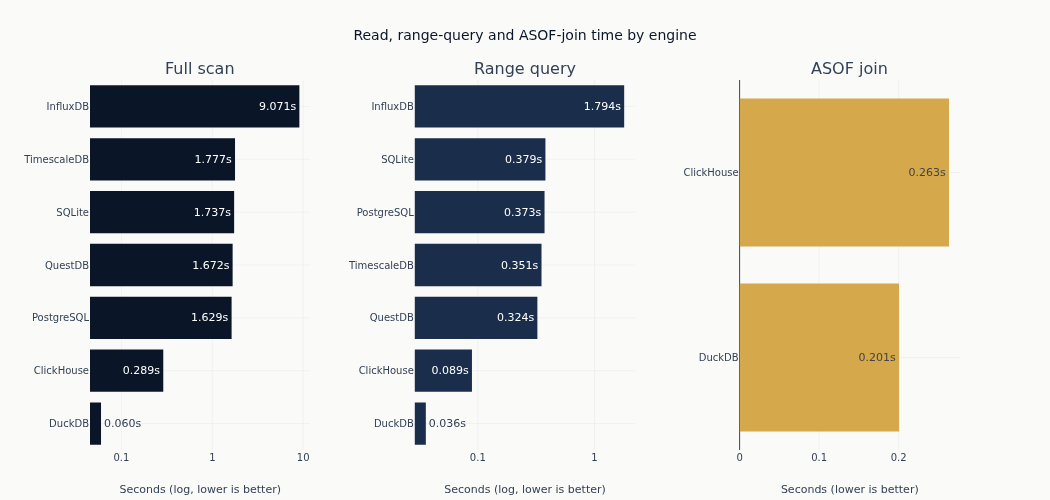

In [50]:
if results:
    _panels = [
        ("read", "Full scan", COLORS["blue"]),
        ("range_query", "Range query", COLORS["slate"]),
        ("asof_join", "ASOF join", COLORS["amber"]),
    ]

    fig = make_subplots(
        rows=1,
        cols=len(_panels),
        subplot_titles=[title for _, title, _ in _panels],
        horizontal_spacing=0.12,
    )

    for col, (op, _title, color) in enumerate(_panels, start=1):
        op_data = results_df.filter(pl.col("operation") == op).sort("time_s")
        if len(op_data) == 0:
            continue
        fig.add_trace(
            go.Bar(
                y=op_data["database"].to_list(),
                x=op_data["time_s"].to_list(),
                orientation="h",
                marker_color=color,
                text=[f"{t:.3f}s" for t in op_data["time_s"].to_list()],
                # "auto" keeps the longest bar's label inside the bar so it does
                # not overrun into the neighbouring panel's y-axis labels; short
                # bars still get an outside label.
                textposition="auto",
                cliponaxis=False,
            ),
            row=1,
            col=col,
        )
        times = op_data["time_s"].to_list()
        spread = max(times) / min(times) if min(times) > 0 else 1.0
        if spread >= LOG_AXIS_RATIO:
            fig.update_xaxes(
                title_text="Seconds (log, lower is better)",
                type="log",
                # One tick per decade. The default labels the minor ticks as well, which
                # on a two-decade axis reads "5 0.1 2 5 1 2" - a 5 to the left of a 0.1.
                dtick=1,
                row=1,
                col=col,
            )
        else:
            fig.update_xaxes(title_text="Seconds (lower is better)", type="linear", row=1, col=col)

    fig.update_layout(
        title_text="Read, range-query and ASOF-join time by engine",
        height=500,
        # Fixed width: the default ~700px crowds eight engines and their value labels.
        width=1050,
        showlegend=False,
        paper_bgcolor=COLORS["bg_light"],
        plot_bgcolor=COLORS["bg_light"],
        # Wider right margin so the 'X.XXXs' value labels don't crop.
        margin=dict(l=90, r=90, t=80, b=50),
    )

    _scale_word = {"S": "Small", "M": "Medium", "L": "Large"}.get(ACTIVE_SCALE, ACTIVE_SCALE)
    print(
        f"Warm reads on a {_scale_word}-scale panel: {total_rows:,} rows, "
        f"{n_sessions} sessions, {len(results_df['database'].unique())} engines. "
        f"Range query covers the first {range_sessions} of {n_sessions} sessions "
        f"({range_share:.1%} of the panel)."
    )
    # Counted off the results, not described: see the markdown above this cell.
    _bars = {op: results_df.filter(pl.col("operation") == op).height for op, _title, _c in _panels}
    show_plotly_with_alt(
        fig,
        "Three horizontal-bar panels titled Full scan, Range query and ASOF join. Each "
        "has one bar per database engine, ordered with the slowest at the top and the "
        "fastest at the bottom, and every bar is labelled with its time in seconds. Not "
        "every engine answers every operation, so the panels differ in height: the "
        f"full-scan panel has {_bars['read']} bars, the range-query panel "
        f"{_bars['range_query']}, and the ASOF-join panel {_bars['asof_join']}, that "
        "last one holding only the engines with a native ASOF join. Each panel's x-axis "
        "is seconds, logarithmic where the engines span a wide range and linear where "
        "they do not, with the axis label saying which.",
    )

In [51]:
if results:
    try:
        fig.write_image(
            OUTPUT_DIR / "server_database_comparison.png", width=1200, height=600, scale=2
        )
    except (RuntimeError, OSError) as exc:
        # Kaleido/Chrome is absent from some benchmark images. Say so rather than
        # passing silently: the book figure is then missing, and a silent skip is
        # indistinguishable from a file that was written.
        print(f"PNG export skipped, the static figure was not written: {exc}")
    save_chart(fig, f"database_comparison_{ACTIVE_SCALE.lower()}")
    save_benchmark_results(results, "databases")

Chart saved: 02_financial_data_universe/.tmp/charts/database_comparison_l.html

📁 Results saved to: 02_financial_data_universe/output/benchmark/databases_l.csv


In [52]:
print("\n### BENCHMARK COVERAGE")
tested = [k for k, v in benchmark_status.items() if v["tested"]]
available = [k for k, v in benchmark_status.items() if v["available"]]
print(f"Tested: {len(tested)}/{len(available)} databases available on this machine")
print(f"Absent: {len(benchmark_status) - len(available)} of {len(benchmark_status)}")
for db in sorted(benchmark_status.keys()):
    entry = benchmark_status[db]
    if entry["tested"]:
        status = "[OK]"
    elif entry["available"]:
        status = "[FAIL]"  # answered the availability check, then did not benchmark
    else:
        status = "absent"  # not reachable here; no result is claimed for it
    print(f"  {status:<8}{db} ({entry['category']})")

print("\n" + "=" * 70)
print("[OK] Database benchmark complete!")
print("=" * 70)


### BENCHMARK COVERAGE
Tested: 7/7 databases available on this machine
Absent: 2 of 9
  absent  ArcticDB (embedded)
  [OK]    ClickHouse (server)
  [OK]    DuckDB (embedded)
  [OK]    InfluxDB (server)
  [OK]    PostgreSQL (server)
  [OK]    QuestDB (server)
  [OK]    SQLite (embedded)
  [OK]    TimescaleDB (server)
  absent  kdb+/PyKX (hft)

[OK] Database benchmark complete!


每项操作最快的引擎，从本次运行实际
收集的结果中回读。未作答的引擎无法出现。

In [53]:
if results:
    fastest = (
        results_df.drop_nulls("time_s")
        .sort("time_s")
        .group_by("operation", maintain_order=True)
        .first()
        .select(["operation", "database", "time_s"])
    )
    print("\nFastest engine per operation (this run):")
    print(fastest)
    print(f"\nEngines benchmarked: {', '.join(sorted(results_df['database'].unique().to_list()))}")


Fastest engine per operation (this run):
shape: (5, 3)
┌─────────────┬──────────┬──────────┐
│ operation   ┆ database ┆ time_s   │
│ ---         ┆ ---      ┆ ---      │
│ str         ┆ str      ┆ f64      │
╞═════════════╪══════════╪══════════╡
│ aggregation ┆ QuestDB  ┆ 0.011771 │
│ range_query ┆ DuckDB   ┆ 0.035878 │
│ read        ┆ DuckDB   ┆ 0.059629 │
│ write       ┆ DuckDB   ┆ 0.130892 │
│ asof_join   ┆ DuckDB   ┆ 0.200558 │
└─────────────┴──────────┴──────────┘

Engines benchmarked: ClickHouse, DuckDB, InfluxDB, PostgreSQL, QuestDB, SQLite, TimescaleDB


## 关键要点

此处没有指明哪个引擎最快。每个操作由哪个引擎最快响应，已根据本次运行在你自己硬件上的结果打印在上方，这可能与我们的结果不同。跨运行一致的是答案的形态：

1. **存储布局决定扫描成本。** 将一列放在一起存储并按批在其上执行的引擎，读取一个分钟级面板的方式，不同于将一行放在一起存储、且为了回答关于两个字段的问题必须触碰全部九个字段的引擎。这种分野——DuckDB 和 ClickHouse 在一侧，SQLite 和 PostgreSQL 在另一侧——是关于引擎如何构建的事实，也是全扫描面板中首先要看的东西。
2. **范围查询与扫描是不同的问题**，而回测问的正是前者。上方的窗口覆盖该面板的前几个交易时段；定义该窗口的单元格会打印出匹配行最终所占的行比例。通过时间分区裁剪或沿时间有序索引遍历的引擎，无需读取其余数据即可回答；而先扫描再过滤的引擎则不能。仅按全扫描排名会掩盖这一差异。留意这个比例：如果窗口覆盖整个面板，那么左侧两个图表面板测量的就是同一个查询。
3. **摄取速率和持久性是一个数，不是两个。** 这里的每个写入时间都在数据可查询时结束，这就是为什么那些提前确认的引擎——通过 ILP 的 QuestDB、InfluxDB——看起来并非没有成本。
4. **每个写入条形都包含一个客户端；其中三个让你看到这部分占多少。** PostgreSQL、TimescaleDB 和 InfluxDB 通过希望每行一个 Python 对象的接口访问，而构建这些对象是一个可单独计时的独立表达式。图表上方的表格给出了该时间。未出现在表中的引擎并非没有客户端成本——它们的转换发生在同时也执行写入的调用内部，无法分离——因此请将该表理解为三个下界，而不是对该领域的划分。
5. **比较的好坏取决于其策略。** 上述每个数字都是每个引擎的一次冷写入和热平均读取。热读取会让任何带有缓冲池的系统显得更好；在冷缓存或跨网络的情况下，压缩型引擎会占优。在选择之前，请在你自己的摄取路径上重新运行。

**kdb+/PyKX** 会被跳过，除非你提供 q 二进制文件和许可证，因此除非你配置了它，否则它不会出现在上述数字中。本章讨论它适用于何处；本 notebook 不会声称它未测量的结果。

**下一步**：参见 `20_storage_benchmark_file` 了解文件格式基准测试（Parquet、Arrow、HDF5）。